Chapter 13 turned molecules into numbers. This chapter uses those numbers to **predict activity**: given a molecule's structure, how strongly will it hit the target? A model that answers this, a **QSAR** (quantitative structure–activity relationship), lets you rank millions of untested molecules and synthesise only the most promising, the computational heart of modern drug discovery. We build one on real data, 600 measured EGFR inhibitors, and, carrying the hard lessons of chapter 8, we are careful to measure its performance honestly, because molecular ML has its own subtle leakage trap.

:::eli5
Chemists have measured, for thousands of molecules, how well each blocks a particular protein. A QSAR model learns the pattern linking a molecule's structure to its strength, then predicts the strength of brand-new molecules it has never seen. If the prediction is even roughly right, you can rank a giant catalogue of molecules and buy or make only the top few hundred instead of testing them all, turning years of lab work into an afternoon of computing. The catch, as always, is making sure the model is genuinely predicting, not just memorising.
:::

## The data: real EGFR inhibitors

We use measured potencies of **EGFR inhibitors** (the lung-cancer target of chapters 11–12) from **ChEMBL**, the main public bioactivity database. Each molecule has an **IC50**: the concentration that gives 50% inhibition (prerequisite P13); lower means more potent. Because IC50 spans many orders of magnitude, we work with **pIC50** = −log₁₀(IC50 in M), so 1 nM becomes 9 and 1 µM becomes 6, higher means more potent, on a friendly linear scale.

607 EGFR inhibitors with measured IC50
pIC50 range 2.2 to 11.0, median 6.3


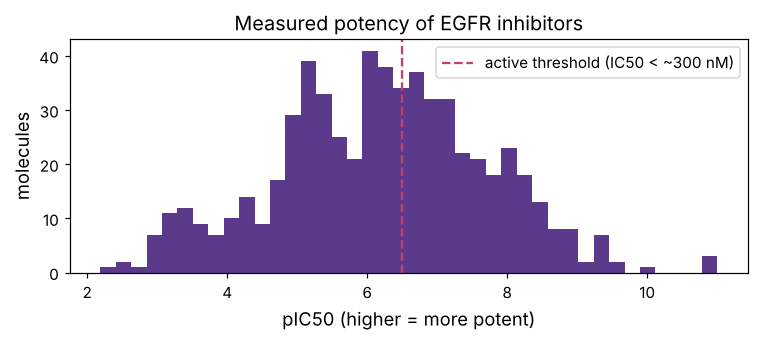

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import AllChem, Descriptors, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit import RDLogger; RDLogger.DisableLog("rdApp.*")
import warnings; warnings.filterwarnings("ignore")

mpl.rc("figure", dpi=110); mpl.rc("axes", labelsize=12, titlesize=13)
IMAGES = Path("images"); IMAGES.mkdir(exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")
R = {}

data = pd.read_csv("datasets/egfr_bioactivity.csv")
data["mol"] = data["smiles"].apply(Chem.MolFromSmiles)
data = data[data["mol"].notna()].reset_index(drop=True)
data["pIC50"] = -np.log10(data["ic50_nM"] * 1e-9)
print(f"{len(data)} EGFR inhibitors with measured IC50")
print(f"pIC50 range {data.pIC50.min():.1f} to {data.pIC50.max():.1f}, median {data.pIC50.median():.1f}")
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(data.pIC50, bins=40, color="#5b3a8c"); ax.axvline(6.5, color="#c2416b", ls="--", label="active threshold (IC50 < ~300 nM)")
ax.set_xlabel("pIC50 (higher = more potent)"); ax.set_ylabel("molecules"); ax.legend()
ax.set_title("Measured potency of EGFR inhibitors")
save_fig("activity_dist"); plt.show()
R["n"] = len(data); R["median_pic50"] = f"{data.pIC50.median():.1f}"

![Figure 14-1. Distribution of measured pIC50 for EGFR inhibitors. The spread of several log units is what a QSAR model must learn to predict from structure.](images/activity_dist.png)

## Featurising molecules, and the leakage trap

We turn each molecule into a **Morgan fingerprint** (chapter 13), the features for our model. But molecular ML has a specific pitfall. Datasets like this contain **series** of closely related molecules (a chemist makes dozens of variants of one scaffold). A random train/test split scatters a series across both sets, so the model can "predict" a test molecule just by having memorised its near-twin in training, exactly the leakage of chapter 8, dressed in chemical clothes. The honest test is a **scaffold split**: group molecules by their core scaffold and keep whole scaffolds together, forcing the model to generalise to *new* chemistry.

In [2]:
def fingerprint(mol, radius=2, n_bits=2048):
    return np.array(AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits))

X = np.array([fingerprint(m) for m in data["mol"]])
y = data["pIC50"].values

def scaffold(mol):
    try:
        return MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    except Exception:
        return ""
data["scaffold"] = data["mol"].apply(scaffold)
n_scaffolds = data["scaffold"].nunique()
print(f"{len(data)} molecules share {n_scaffolds} distinct scaffolds (many series of analogues)")
R["n_scaffolds"] = n_scaffolds

607 molecules share 160 distinct scaffolds (many series of analogues)


## Building and validating the model

A **random forest** (chapter 8) is a strong, robust default for fingerprint-based QSAR. We evaluate it two ways, random split and scaffold split, to expose the leakage difference.

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupShuffleSplit, ShuffleSplit
from sklearn.metrics import r2_score, mean_absolute_error

def evaluate(splitter, groups=None):
    r2s, maes = [], []
    for train, test in splitter.split(X, y, groups):
        rf = RandomForestRegressor(300, random_state=0, n_jobs=-1).fit(X[train], y[train])
        p = rf.predict(X[test])
        r2s.append(r2_score(y[test], p)); maes.append(mean_absolute_error(y[test], p))
    return np.mean(r2s), np.mean(maes)

r2_rand, mae_rand = evaluate(ShuffleSplit(5, test_size=0.2, random_state=0))
r2_scaf, mae_scaf = evaluate(GroupShuffleSplit(5, test_size=0.2, random_state=0), groups=data["scaffold"])
print(f"random split:   R2 = {r2_rand:.2f}, MAE = {mae_rand:.2f} log units")
print(f"scaffold split: R2 = {r2_scaf:.2f}, MAE = {mae_scaf:.2f} log units")
R["r2_rand"] = f"{r2_rand:.2f}"; R["r2_scaf"] = f"{r2_scaf:.2f}"; R["mae_scaf"] = f"{mae_scaf:.2f}"

random split:   R2 = 0.70, MAE = 0.59 log units
scaffold split: R2 = 0.65, MAE = 0.67 log units


The two numbers tell the real story: the random split reports R² = 0.70, but the honest scaffold split reports 0.65, lower, because predicting activity for a genuinely new scaffold is harder than interpolating within a known series. **The scaffold-split number is the one that matters** for whether the model helps with new chemistry. Reporting the random-split number (as many papers do) overstates what the model can do, the same honesty lesson as chapter 8. A typical error of about 0.67 log units means predictions are good to roughly a factor of a few in IC50, enough to prioritise, not enough to trust blindly.

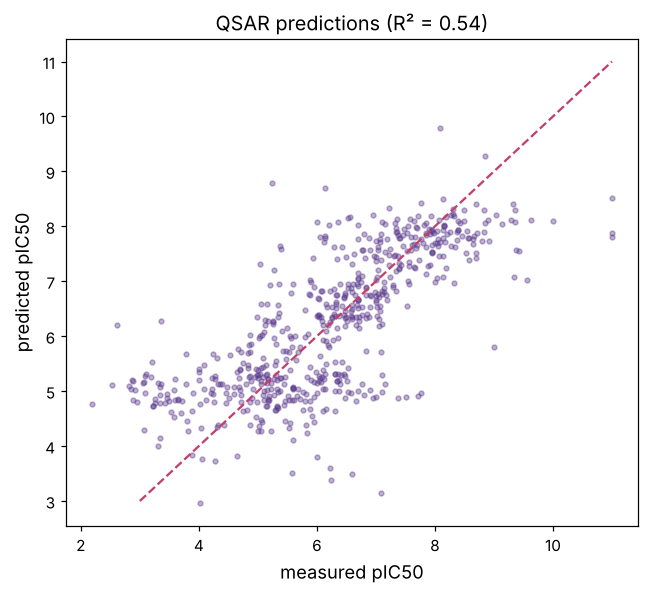

In [4]:
from sklearn.model_selection import cross_val_predict
pred = cross_val_predict(RandomForestRegressor(200, random_state=0, n_jobs=-1), X, y, cv=5)
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(y, pred, s=10, alpha=0.4, color="#5b3a8c")
ax.plot([3, 11], [3, 11], color="#c2416b", ls="--")
ax.set_xlabel("measured pIC50"); ax.set_ylabel("predicted pIC50")
ax.set_title(f"QSAR predictions (R² = {r2_score(y, pred):.2f})")
save_fig("predictions"); plt.show()

![Figure 14-2. Cross-validated predicted versus measured potency. Points cluster around the diagonal; the model captures the broad potency trend from structure alone, with scatter from activity cliffs and novel chemistry.](images/predictions.png)

The playground's first tab shows this predicted-vs-measured scatter.

::playground animations/qsar_lab.html 640

## Classification: active or not?

Often you just need a yes/no: is a molecule **active** (worth testing) or not? We define active as potent enough (say IC50 < 300 nM, pIC50 > 6.5) and train a classifier, evaluating with the **ROC AUC** and the **precision** among top predictions.

43% of molecules are 'active' (pIC50 > 6.5)


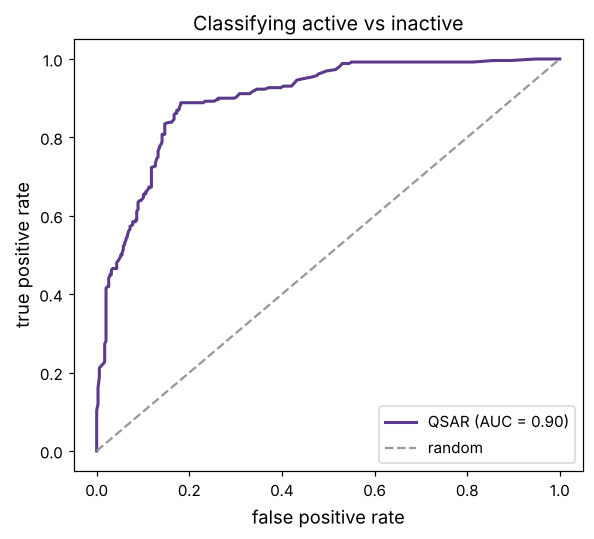

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
active = (y > 6.5).astype(int)
print(f"{active.mean():.0%} of molecules are 'active' (pIC50 > 6.5)")
proba = cross_val_predict(RandomForestClassifier(300, random_state=0, n_jobs=-1), X, active, cv=5, method="predict_proba")[:, 1]
auc = roc_auc_score(active, proba)
fpr, tpr, _ = roc_curve(active, proba)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot(fpr, tpr, color="#5b3a8c", lw=2, label=f"QSAR (AUC = {auc:.2f})")
ax.plot([0, 1], [0, 1], color="0.6", ls="--", label="random")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(); ax.set_title("Classifying active vs inactive")
save_fig("roc"); plt.show()
R["auc"] = f"{auc:.2f}"

![Figure 14-3. ROC curve for classifying EGFR inhibitors as active or inactive. The model ranks actives above inactives far better than chance.](images/roc.png)

The classifier reaches AUC 0.90: given a random active and a random inactive, it ranks the active higher 0.90 of the time. That ranking ability is exactly what virtual screening needs.

## Virtual screening and enrichment

The payoff: use the model to **rank a library** and test only the top slice. The right metric is **enrichment**, how many more actives you find in the top fraction than you would at random. We simulate screening our molecules (ranked by the model) and plot the fraction of actives recovered against the fraction tested.

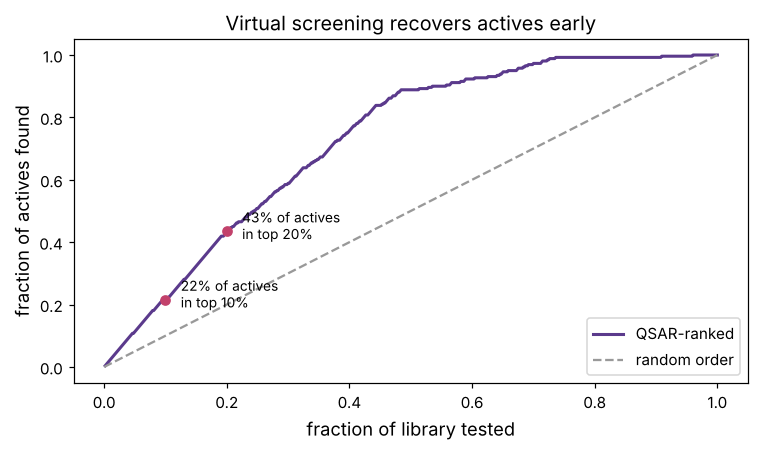

In [6]:
order = np.argsort(proba)[::-1]                              # rank by predicted activity
recovered = np.cumsum(active[order]) / active.sum()
fraction_tested = np.arange(1, len(y) + 1) / len(y)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(fraction_tested, recovered, color="#5b3a8c", lw=2, label="QSAR-ranked")
ax.plot([0, 1], [0, 1], color="0.6", ls="--", label="random order")
for frac in [0.1, 0.2]:
    idx = int(frac * len(y))
    ax.scatter(frac, recovered[idx], color="#c2416b", zorder=3)
    ax.annotate(f"{recovered[idx]:.0%} of actives\nin top {frac:.0%}", (frac, recovered[idx]), xytext=(10, -5), textcoords="offset points", fontsize=9)
ax.set_xlabel("fraction of library tested"); ax.set_ylabel("fraction of actives found"); ax.legend(loc="lower right")
ax.set_title("Virtual screening recovers actives early")
save_fig("enrichment"); plt.show()
ef10 = recovered[int(0.1 * len(y))] / 0.1
R["ef10"] = f"{ef10:.1f}"; R["recov10"] = f"{recovered[int(0.1*len(y))]:.0%}"

![Figure 14-4. Enrichment curve: the model-ranked order (purple) recovers actives much faster than random (dashed). Testing the top 10% finds far more than 10% of the actives.](images/enrichment.png)

Testing just the top 10% recovers 22% of all actives, an **enrichment factor** of about 2.2× over random. On a real library of millions, where actives might be 1 in 10,000, that multiplier is the difference between a feasible screen and an impossible one. The playground's second tab lets you slide the tested fraction and read off the recovery.

## The applicability domain: knowing what you don't know

A QSAR model is only trustworthy for molecules *similar to its training set*. Ask it about a wildly different molecule and it will still return a number, confidently and wrongly. The **applicability domain** is the region of chemical space where predictions can be believed. A simple check: a prediction is reliable only if the molecule is within some Tanimoto similarity of the training set.

In [7]:
from rdkit import DataStructs
from sklearn.model_selection import train_test_split
tr, te = train_test_split(np.arange(len(data)), test_size=0.3, random_state=1)
train_fps = [AllChem.GetMorganFingerprintAsBitVect(data["mol"][i], 2, 2048) for i in tr]
rf = RandomForestRegressor(300, random_state=0, n_jobs=-1).fit(X[tr], y[tr])
errors, similarities = [], []
for i in te:
    fp = AllChem.GetMorganFingerprintAsBitVect(data["mol"][i], 2, 2048)
    max_sim = max(DataStructs.BulkTanimotoSimilarity(fp, train_fps))
    errors.append(abs(rf.predict(X[i:i+1])[0] - y[i])); similarities.append(max_sim)
errors, similarities = np.array(errors), np.array(similarities)
near, far = similarities > 0.5, similarities <= 0.5
print(f"molecules similar to training (Tanimoto > 0.5): MAE {errors[near].mean():.2f}")
print(f"molecules far from training (Tanimoto <= 0.5): MAE {errors[far].mean():.2f}")
R["mae_near"] = f"{errors[near].mean():.2f}"; R["mae_far"] = f"{errors[far].mean():.2f}"

molecules similar to training (Tanimoto > 0.5): MAE 0.52
molecules far from training (Tanimoto <= 0.5): MAE 0.97


Predictions for molecules close to the training set are much more accurate (0.52 log units) than for distant ones (0.97). A responsible virtual screen reports, with every prediction, whether the molecule is inside the applicability domain, and treats out-of-domain predictions with scepticism. Ignoring this is a classic way QSAR models disappoint in practice.

:::idea
Fingerprints plus a random forest is a strong, hard-to-beat baseline, and for years it was the state of the art. Today, **graph neural networks** (which learn features directly from the molecular graph, chapter 9's idea applied to molecules) and **pretrained molecular models** (like protein language models, chapter 10, but for chemistry) push accuracy further, especially with large datasets. But they share every pitfall here: they need scaffold-split validation, an applicability domain, and honest reporting. More powerful models make honest evaluation *more* important, not less, because they are better at finding shortcuts.
:::

## Summary

| Idea | One line |
|---|---|
| QSAR | predict activity (pIC50) from molecular structure |
| pIC50 | −log of IC50; higher = more potent; linear and friendly |
| Scaffold split | the honest test: hold out whole scaffolds, not random molecules |
| Random forest | strong fingerprint-based QSAR baseline |
| Classification / AUC | active vs inactive; ranking ability |
| Virtual screening | rank a library, test the top; measured by enrichment |
| Applicability domain | trust predictions only for molecules like the training set |

:::check
1. Why work with pIC50 instead of raw IC50? *(IC50 spans orders of magnitude; the log makes a linear, well-behaved target, and higher = more potent.)*
2. Why is a random train/test split misleading for molecular data? *(Series of analogues leak across the split; a scaffold split forces generalisation to new chemistry.)*
3. A model has random-split R² 0.8 but scaffold-split R² 0.4. Which do you report, and why? *(The scaffold split: it reflects performance on genuinely new molecules.)*
4. What does an enrichment factor of 10 at 1% mean? *(Testing the top 1% finds 10× more actives than testing 1% at random.)*
5. Why does a QSAR model need an applicability domain? *(It is only reliable for molecules similar to its training set; it returns confident but wrong numbers for very different ones.)*
:::

:::exercise
Compare fingerprints with simple descriptors as features. (a) Build a second model using just the handful of physicochemical descriptors from chapter 13 (MW, logP, HBD, HBA, TPSA, rotatable bonds) instead of the 2048-bit fingerprint. (b) Evaluate both with a scaffold split. (c) Which does better, and why might a tiny descriptor set still do respectably? When would you prefer the interpretable descriptor model over the fingerprint one?
:::

<details><summary>Solution</summary>

In [8]:
desc_names = ["MolWt", "MolLogP", "NumHDonors", "NumHAcceptors", "TPSA", "NumRotatableBonds"]
from rdkit.Chem import Descriptors as D
def desc_vector(m):
    return [D.MolWt(m), D.MolLogP(m), D.NumHDonors(m), D.NumHAcceptors(m), D.TPSA(m), D.NumRotatableBonds(m)]
Xd = np.array([desc_vector(m) for m in data["mol"]])
r2_fp, _ = evaluate(GroupShuffleSplit(5, test_size=0.2, random_state=0), groups=data["scaffold"])
r2d = []
for train, test in GroupShuffleSplit(5, test_size=0.2, random_state=0).split(Xd, y, data["scaffold"]):
    rf = RandomForestRegressor(300, random_state=0, n_jobs=-1).fit(Xd[train], y[train])
    r2d.append(r2_score(y[test], rf.predict(Xd[test])))
print(f"fingerprint scaffold-split R2: {r2_fp:.2f}")
print(f"6-descriptor scaffold-split R2: {np.mean(r2d):.2f}")

fingerprint scaffold-split R2: 0.65
6-descriptor scaffold-split R2: 0.27


The fingerprint model usually wins, because fingerprints capture the specific substructures that determine binding, while six global descriptors capture only coarse properties. But the descriptor model is often not far behind, because potency correlates with gross properties like size and lipophilicity (bigger, greasier molecules often bind the hydrophobic kinase pocket better, chapter 11), so even crude features explain part of the variance. You would prefer the descriptor model when you need **interpretability** (which property to change to improve potency), when data is scarce (few features resist overfitting), or when you must predict for molecules far outside the fingerprint space of your training set. In practice, people often combine both, and add many more descriptors, then let the model and honest validation decide.

</details>